In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from itertools import permutations
import matplotlib as mpl
from ou_hankel import (OUNetwork,
                       empirical_kalman_causality_probability)
import pandas as pd
plt.rcParams.update({
    # Font Family
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
    
    # Consistent Font Sizes
    'font.size': 13,          # Base default text size
    'axes.labelsize': 13,     # X and Y axis labels
    'axes.titlesize': 13,     # Subplot titles
    'xtick.labelsize': 13,    # X-axis tick labels
    'ytick.labelsize': 13,    # Y-axis tick labels
    'legend.fontsize': 10,   # Legend text
    'figure.titlesize': 10,   # Overall figure title
})
df = pd.read_csv("Police_data.csv")


In [11]:
L = 23
lista = ["Atlanta-Sandy Springs-Alpharetta, GA MSA",
    "Baltimore-Columbia-Towson, MD MSA",
    "Boston-Cambridge-Newton, MA-NH MSA",
    "Chicago-Naperville-Elgin, IL-IN-WI MSA",
    "Dallas-Fort Worth-Arlington, TX MSA",
    "Denver-Aurora-Lakewood, CO MSA",
    "Detroit_Dearborn, MI MSA",
    "Houston-The Woodlands-Sugar Land, TX MSA",
    "Los Angeles-Long Beach-Anaheim, CA MSA",
    "Miami-Fort Lauderdale-West Palm Beach, FL MSA",
    "Minneapolis-St. Paul-Bloomington, MN-WI MSA",
    "New York-Newark-Jersey City, NY-NJ-PA MSA",
    "Philadelphia-Camden-Wilmington, PA-NJ-DE-MD MSA",
    "Phoenix-Mesa-Chandler, AZ MSA",
    "Riverside-San Bernardino-Ontario, CA MSA",
    "San Francisco-Oakland-Berkeley, CA MSA",
    "Tampa-St. Petersburg-Clearwater, FL MSA",
    "Washington-Arlington-Alexandria, DC-VA-MD-WV MSA"]

# 1. Sweep and create results_df
nodes = ["PT", "NT", "CR", "PB"]
results = []

for arg in lista:
    cols = [
        f"Tweet search - {arg}_sent_Hugged_Positive_sa_det",
        f"Tweet search - {arg}_sent_Hugged_Negative_sa_det",
        f"{arg}_crimes_lagged_sa_det",
        "Police_Brutality_lagged_sa_det",
    ]
    X = df[cols].to_numpy()
    for i, j in permutations(range(4), 2):
        out = empirical_kalman_causality_probability(X, [i], [j], L)
        results.append((arg, nodes[i], nodes[j], i, j, out["log_odds"]))

results_df = pd.DataFrame(
    results, columns=["Arg", "Cause", "Target", "Idx_i", "Idx_j", "LogOdds"]
)

# 2. Filter & Plot Network
threshold = 0
counts = (
    results_df[results_df["LogOdds"] > threshold]
    .groupby(["Cause", "Target"])
    .size()
)

G = nx.DiGraph()
G.add_nodes_from(nodes)
pos = nx.circular_layout(G)

edges = list(counts.index)
weights = counts.values


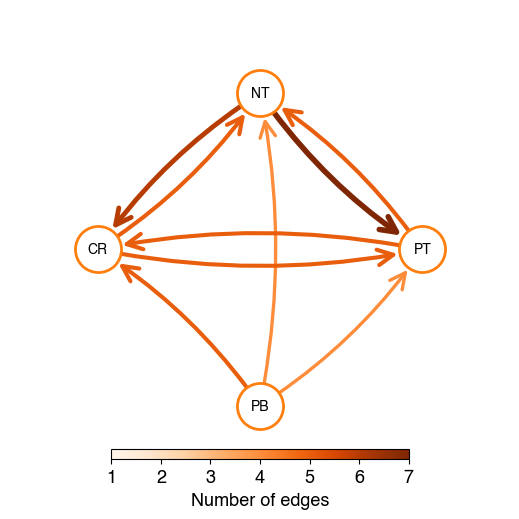

In [12]:
fig,ax = plt.subplots(figsize=(5,5))

nx.draw_networkx_nodes(
    G,pos,node_size=1100,node_color="white",
    edgecolors="tab:orange",linewidths=2,ax=ax)

nx.draw_networkx_labels(
    G,pos,font_weight="normal",font_size=10,
    font_color="black",ax=ax)

if edges:
    weights = np.asarray(weights)
    wmin,wmax = 1,weights.max()

    cmap = plt.cm.Oranges
    norm = mpl.colors.Normalize(wmin,wmax)

    edge_colors = cmap(norm(weights))
    widths = 0.8 + 3.2*(weights-wmin)/max(wmax-wmin,1)

    # Draw weak edges first, strong/thick edges last
    order = np.argsort(widths)

    nx.draw_networkx_edges(
        G,pos,edgelist=[edges[i] for i in order],
        edge_color=[edge_colors[i] for i in order],
        width=[widths[i] for i in order],
        arrowsize=28,arrowstyle="->",
        connectionstyle="arc3,rad=0.1",
        node_size=1100,min_source_margin=12,
        min_target_margin=18,ax=ax)

    sm = mpl.cm.ScalarMappable(cmap=cmap,norm=norm)
    sm.set_array([])

    cbar = fig.colorbar(
        sm,ax=ax,orientation="horizontal",
        fraction=0.022,pad=-0.09,shrink=0.95,
        aspect=30)

    cbar.set_label("Number of edges")
    cbar.set_ticks(np.arange(wmin,wmax+1))

ax.set_facecolor("white")
ax.margins(.20)
ax.axis("off")

plt.tight_layout(pad=0)
plt.savefig("plots/Figure6.pdf",bbox_inches="tight")
plt.show()

In [4]:
df

,Unnamed: 0,Ref_Date,"Tweet search - Atlanta-Sandy Springs-Alpharetta, GA MSA_sent_Hugged_Positive","Tweet search - Atlanta-Sandy Springs-Alpharetta, GA MSA_sent_Hugged_Negative","Tweet search - Baltimore-Columbia-Towson, MD MSA_sent_Hugged_Positive","Tweet search - Baltimore-Columbia-Towson, MD MSA_sent_Hugged_Negative","Tweet search - Boston-Cambridge-Newton, MA-NH MSA_sent_Hugged_Positive","Tweet search - Boston-Cambridge-Newton, MA-NH MSA_sent_Hugged_Negative","Tweet search - Chicago-Naperville-Elgin, IL-IN-WI MSA_sent_Hugged_Positive","Tweet search - Chicago-Naperville-Elgin, IL-IN-WI MSA_sent_Hugged_Negative",...,"Philadelphia-Camden-Wilmington, PA-NJ-DE-MD MSA_crimes_lagged_sa_det","Atlanta-Sandy Springs-Alpharetta, GA MSA_crimes_lagged_sa_det","Miami-Fort Lauderdale-West Palm Beach, FL MSA_crimes_lagged_sa_det","Phoenix-Mesa-Chandler, AZ MSA_crimes_lagged_sa_det","Boston-Cambridge-Newton, MA-NH MSA_crimes_lagged_sa_det","San Francisco-Oakland-Berkeley, CA MSA_crimes_lagged.1_sa_det","Minneapolis-St. Paul-Bloomington, MN-WI MSA_crimes_lagged_sa_det","Tampa-St. Petersburg-Clearwater, FL MSA_crimes_lagged_sa_det","Denver-Aurora-Lakewood, CO MSA_crimes_lagged_sa_det","Baltimore-Columbia-Towson, MD MSA_crimes_lagged_sa_det"
0,0,2010-10-01 00:00:00+00:00,1,0,0,1,1,3,1,7,...,0.718682,0.555134,0.968274,-1.418904,1.399561,0.952305,-0.271054,0.042479,0.005852,1.825122
1,1,2010-10-02 00:00:00+00:00,0,1,1,1,0,5,0,0,...,-1.039865,-1.384707,-0.384025,-1.318400,1.268672,-1.092086,-0.405328,1.075212,0.080295,1.152312
2,2,2010-10-03 00:00:00+00:00,1,2,0,4,0,1,0,3,...,2.002314,-1.013134,1.351646,-0.713268,0.184239,-1.570037,-0.136482,0.810649,0.563463,2.011598
3,3,2010-10-04 00:00:00+00:00,1,4,0,9,0,0,1,6,...,-0.045216,-0.970814,-0.085841,-1.118873,1.164497,2.882573,-0.290864,0.137825,0.850895,0.305677
4,4,2010-10-05 00:00:00+00:00,1,0,0,6,0,3,1,3,...,-1.864624,-1.538806,0.020878,-2.782065,3.070940,0.967111,-0.618173,0.247216,0.834331,1.314451
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3740,3740,2020-12-27 00:00:00+00:00,2,9,0,3,1,4,4,25,...,-0.182134,3.274689,0.669410,0.776847,-0.413606,0.262774,-0.388326,-0.100116,-0.256590,-0.010136
3741,3741,2020-12-28 00:00:00+00:00,2,4,0,5,1,4,2,11,...,0.757027,0.240156,0.959048,0.548666,0.738982,0.206044,1.665580,0.047949,0.274079,-0.640642
3742,3742,2020-12-29 00:00:00+00:00,4,11,1,3,0,6,3,16,...,0.174310,1.976421,0.078056,-0.177272,-0.279187,-0.536441,0.365423,-0.567749,-0.209850,-1.639001
3743,3743,2020-12-30 00:00:00+00:00,0,10,0,11,0,8,0,18,...,0.938852,-1.185869,-0.317928,0.926442,-0.255807,0.191595,0.639010,0.016961,0.187233,1.227381
